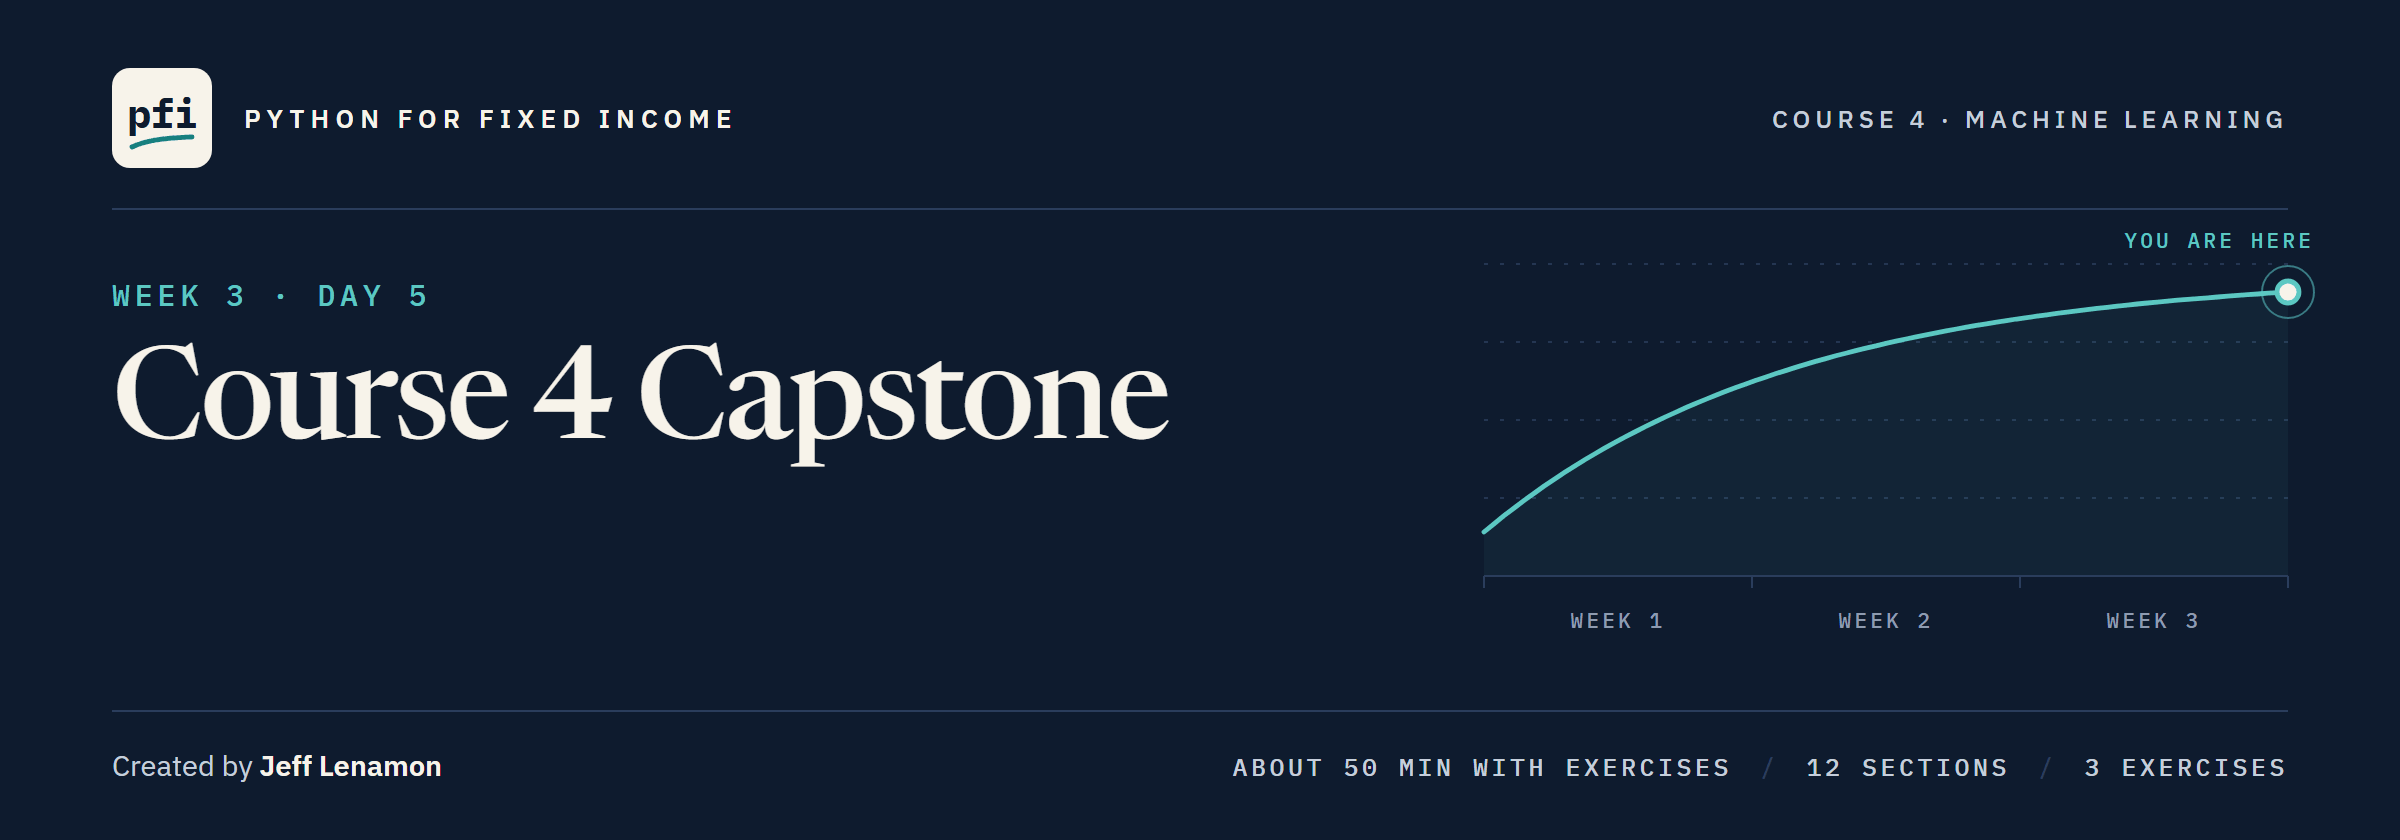

# Course 4 Capstone

Week 3, Day 5. Run the whole course on one real file: describe it, look at it without the label, choose a model and a threshold on folds of the training rows, open the test rows once, and say where the model fails.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day5/course4_capstone.ipynb)

# Problem Statement

## Business Context

A colleague who covers emerging market corporates hands you a public file: financial statements of Polish companies, 64 ratios each, and a flag for the companies that went bankrupt within a year.
The dataset page says the bankrupt companies were analysed from 2000 to 2012 and the ones still operating from 2007 to 2013 ([dataset page](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data)).
It is one country in one period, and that market differs from US credit.
She asks which of three standard models best separates the companies that went bankrupt, how well on companies it never saw, and where it fails.
A model's output here is "the model's probability of bankruptcy in this file", or "flagged at threshold t", never a credit view on any company.
The work is yours: each question has an empty cell and a `check()` line, and the solutions notebook is one worked answer.

## Objectives

Describe the file's gaps, copies and extremes, and look at it without the label.
Fit a logistic regression and two pruned trees inside pipelines, and choose every setting and a threshold for a recall of 0.70 on folds of the training rows.
Open the test rows once, then describe what the chosen model leans on and where it fails.

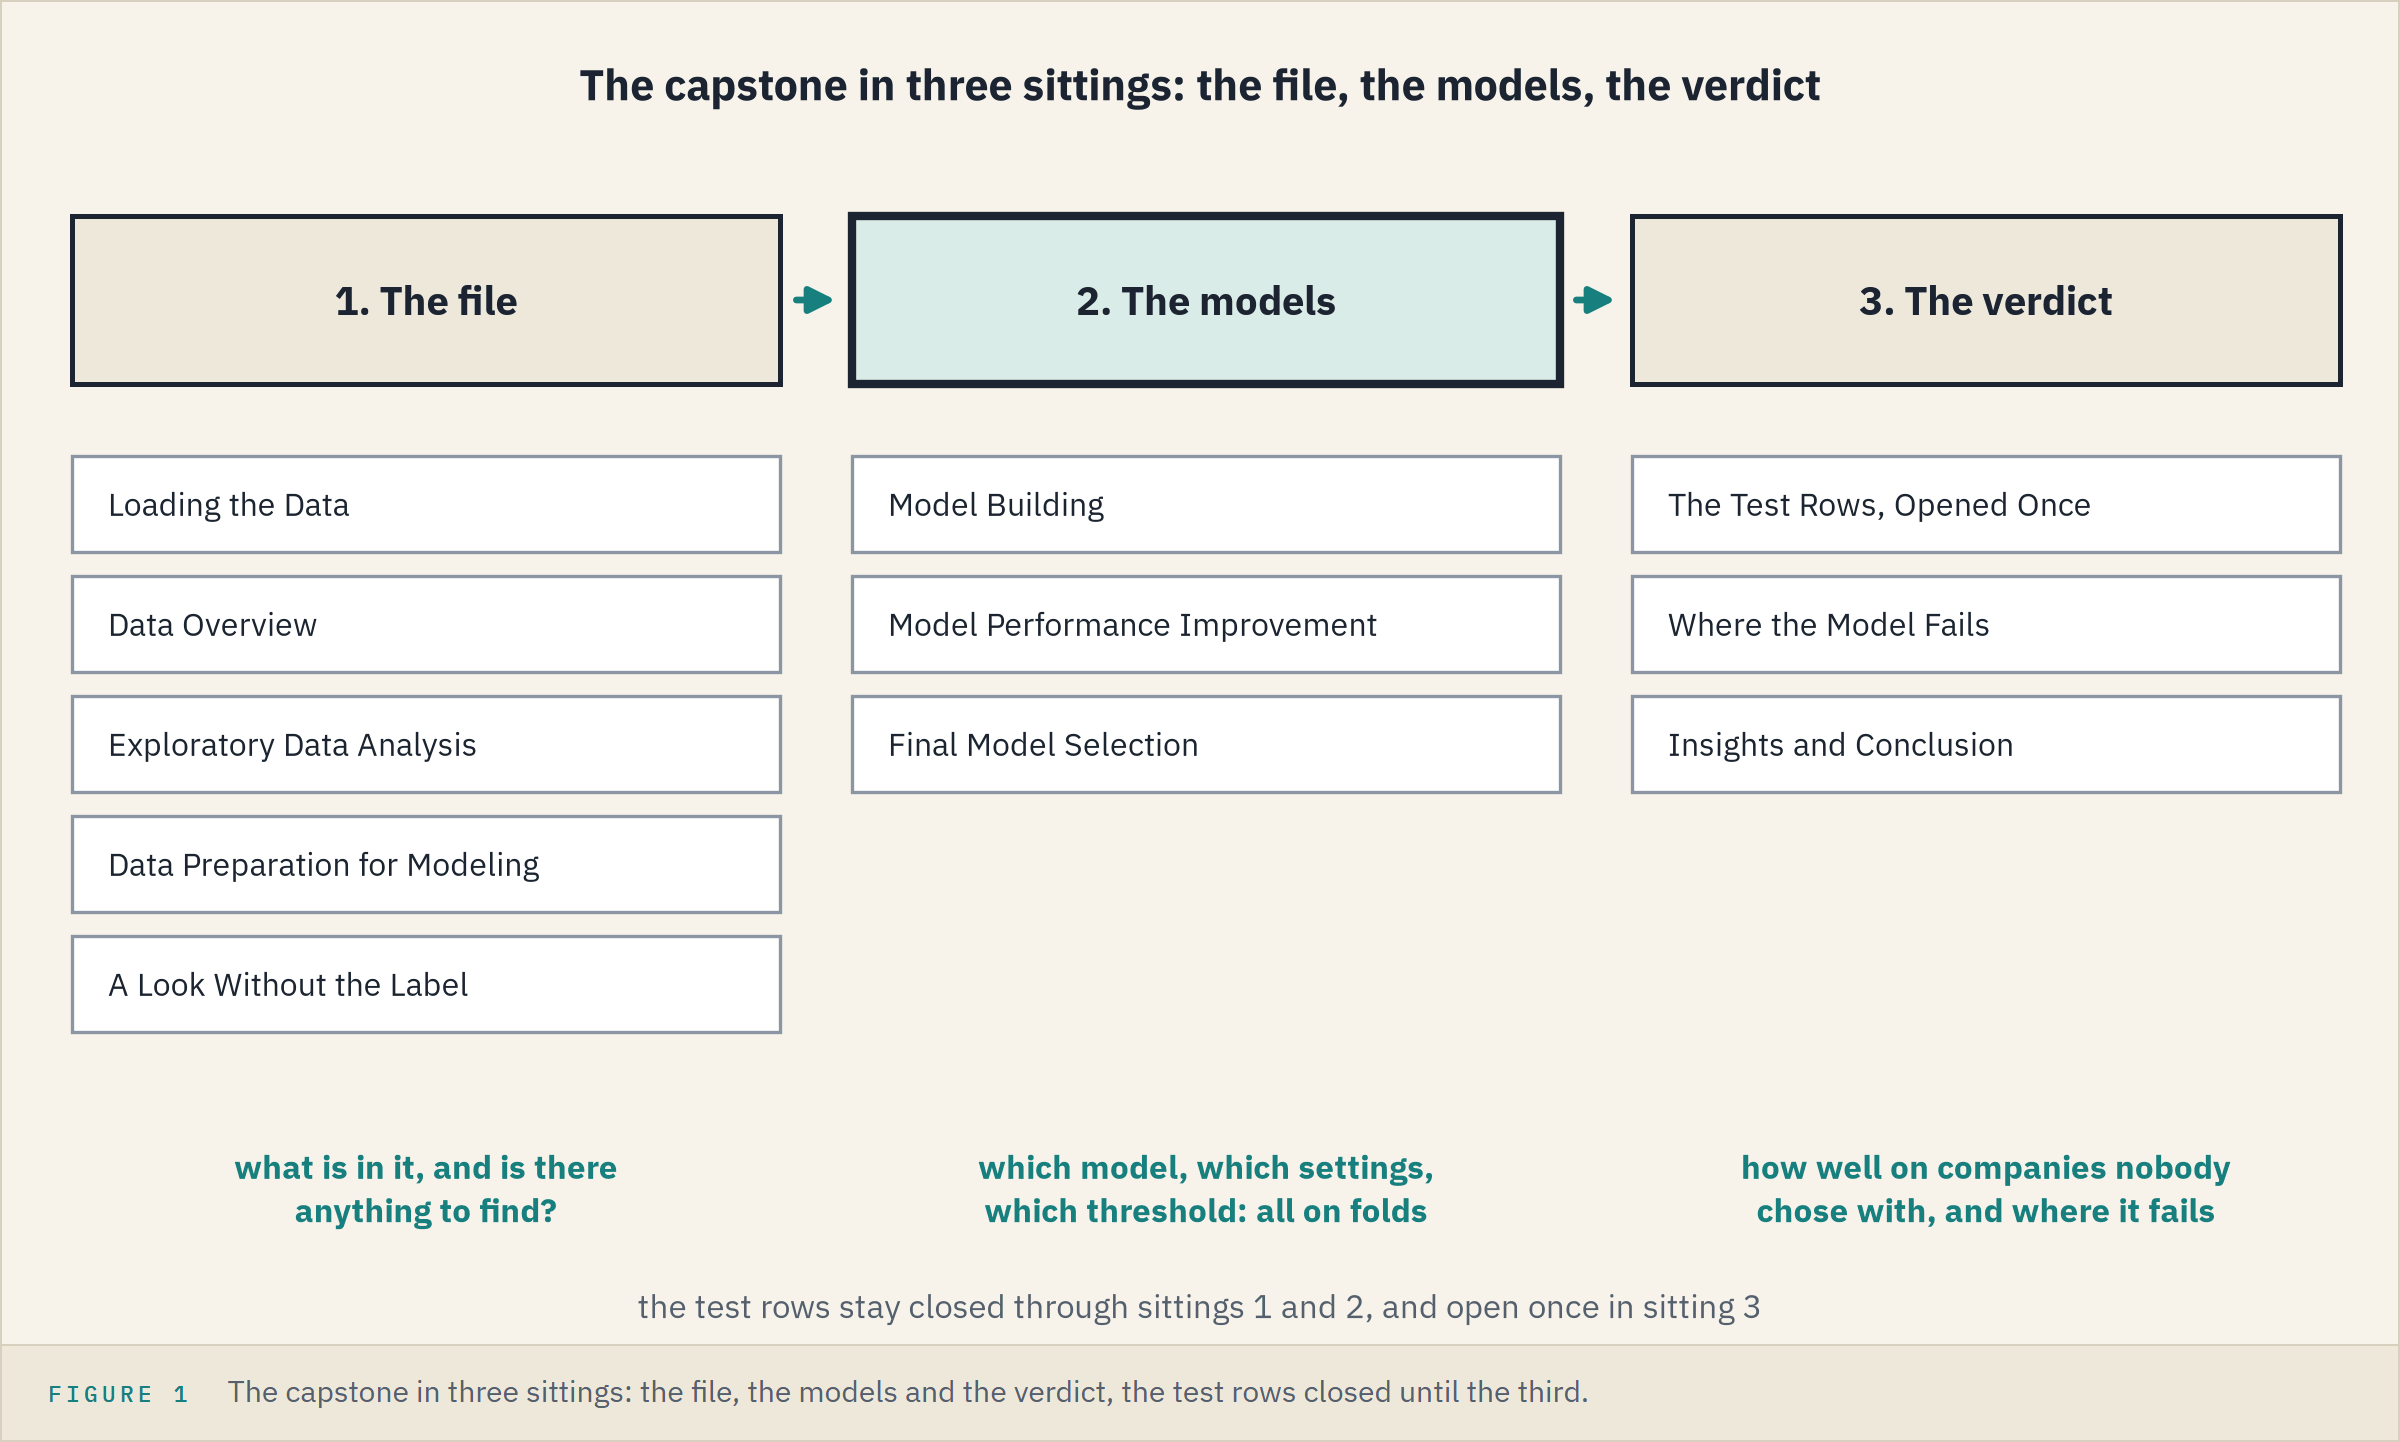

## Data Dictionary

`polish_bankruptcy_5year.csv`, one row per financial statement:

1. `Attr1` to `Attr64`: the 64 features, the page's X1 to X64 in order (the file proves it below)
2. `class`: 1 if the company went bankrupt within a year, **the target**

The features this notebook names, as the page defines them:

- `Attr2` (X2): total liabilities / total assets
- `Attr17` (X17): total assets / total liabilities
- `Attr21` (X21): sales (n) / sales (n-1)
- `Attr27` (X27): profit on operating activities / financial expenses
- `Attr32` (X32): (current liabilities x 365) / cost of products sold
- `Attr33` (X33): operating expenses / short-term liabilities
- `Attr37` (X37): (current assets - inventories) / long-term liabilities
- `Attr39` (X39): profit on sales / sales
- `Attr60` (X60): sales / inventory
- `Attr63` (X63): sales / short-term liabilities

Most features are ratios; X29 is a logarithm of total assets, X55 is working capital (an amount), and nine, X32 among them, are in days.
The provider kept only statements with `Attr20` present, a filter named in the header of the fifth-year file in the [UCI download](https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip), so `Attr20` never has a gap.

## Your Route Through Day 5

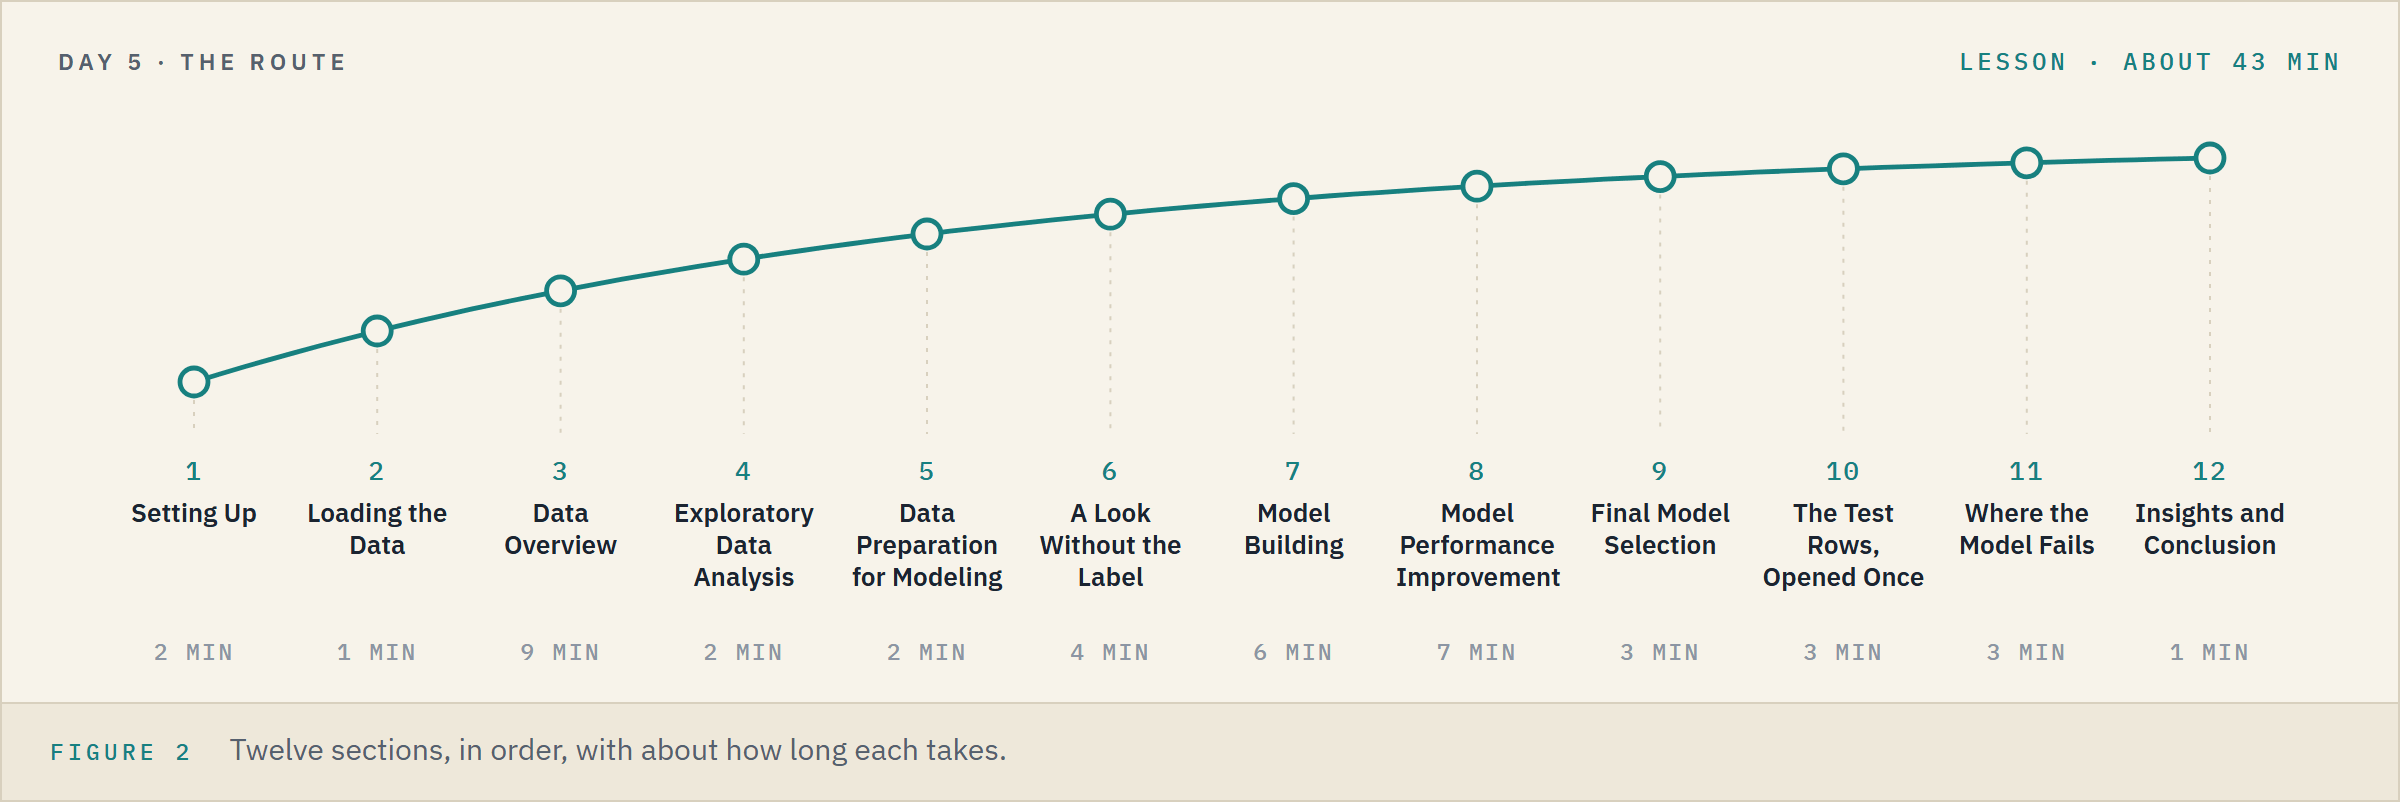

**Time.** About 43 minutes for the lesson, then about 9 for the three exercises.

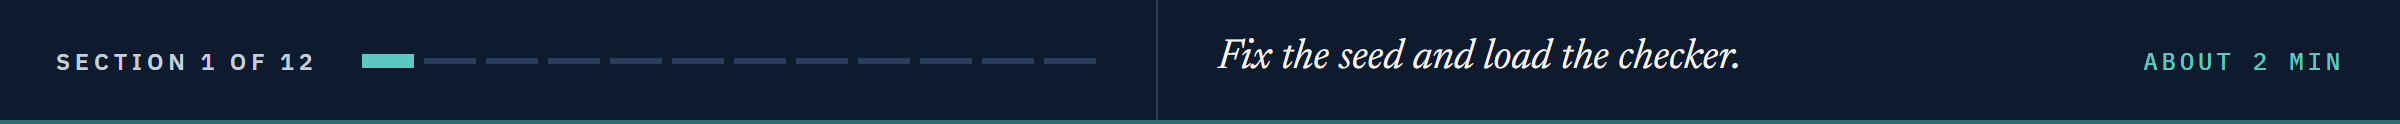

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# to split the rows, fold them, choose settings, and score each row out of fold
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV

# the steps of a pipeline, and the models
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

# to score flags and rankings
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts, the same on Days 7 to 10
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is written on the page.
A number is rounded to the places its question asks for, so you need not round it yourself.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

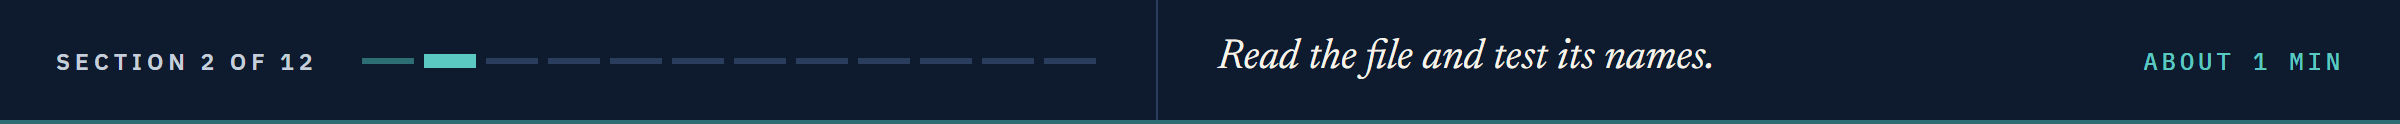

# Loading the Data

## Reading the File

In [4]:
# the 5,910 statements: 64 features named Attr1 to Attr64, and the outcome in class
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]
print(len(FEATURES), "features")

64 features


## The File Proves Its Own Names

The page's X17 is the reciprocal of its X2, so if the file's names follow the page, `Attr17` x `Attr2` is 1.

5890 of 5891 rows have Attr17 x Attr2 within 1 percent of 1


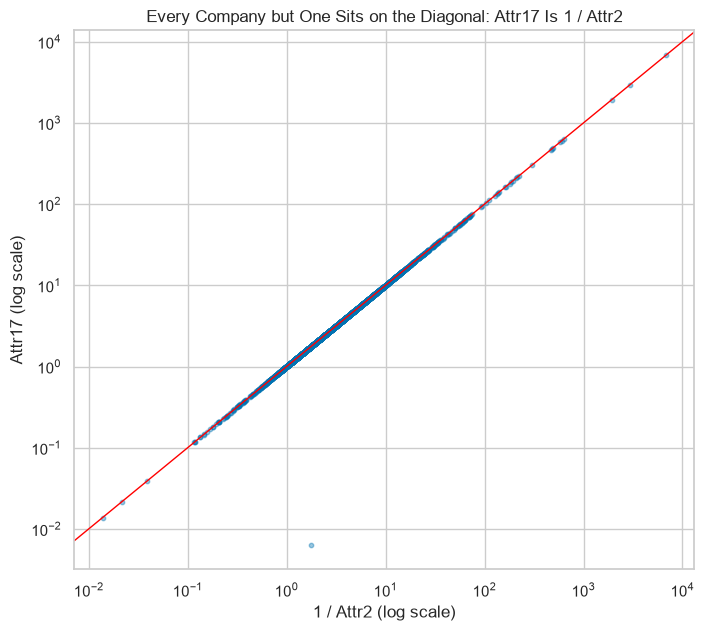

In [5]:
# the rows with both features; if the names follow the page, Attr17 x Attr2 is 1
both = bankrupt[["Attr2", "Attr17"]].dropna()
within = ((both["Attr17"] * both["Attr2"]) - 1).abs() < 0.01
print(within.sum(), "of", len(both), "rows have Attr17 x Attr2 within 1 percent of 1")

# Attr17 against 1 / Attr2 on log axes, the diagonal where the two are equal
plt.figure(figsize=(8, 7))
plt.scatter(1 / both["Attr2"], both["Attr17"], s=10, alpha=0.4)
plt.axline((1, 1), (10, 10), color="red", linewidth=1)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("1 / Attr2 (log scale)")
plt.ylabel("Attr17 (log scale)")
plt.title("Every Company but One Sits on the Diagonal: Attr17 Is 1 / Attr2")
plt.show()

5,890 of 5,891 rows sit on the diagonal, so `Attr`k is read as the page's Xk from here on.

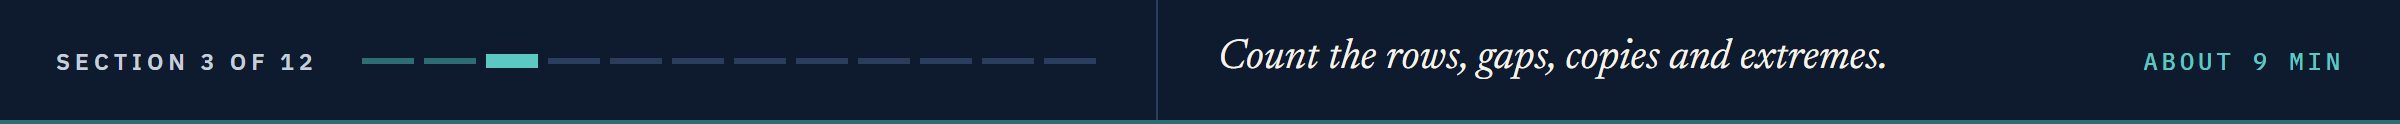

# Data Overview

## Shape, Outcome and Dates

Q. How many rows does the file hold, how many companies went bankrupt, and what share is that in percent? How many columns hold decimal numbers (`float64`)? Store them in `q1_rows`, `q1_bankrupt`, `q1_share` (2 decimals) and `q1_decimal_columns`.

In [6]:
# your code here
q1_rows = ...
q1_bankrupt = ...
q1_share = ...
q1_decimal_columns = ...

In [7]:
check("Q1 rows", q1_rows, "e153ee97eb46", places=0)
check("Q1 bankrupt companies", q1_bankrupt, "43ab3e2ff147", places=0)
check("Q1 bankrupt share", q1_share, "6b33f06c8c1e", places=2)
check("Q1 decimal columns", q1_decimal_columns, "12f77c444b55", places=0)

Q1 rows: not attempted yet
Q1 bankrupt companies: not attempted yet
Q1 bankrupt share: not attempted yet
Q1 decimal columns: not attempted yet


## Missing Values

Q. How many cells are empty, how many columns and how many rows have at least one gap, and which column has the most? Store them in `q2_cells`, `q2_columns`, `q2_rows` and `q2_worst` (the column's name).

In [8]:
# your code here
q2_cells = ...
q2_columns = ...
q2_rows = ...
q2_worst = ...

In [9]:
check("Q2 empty cells", q2_cells, "d7584fbce696", places=0)
check("Q2 columns with a gap", q2_columns, "83cef8e1fd3b", places=0)
check("Q2 rows with a gap", q2_rows, "5a62d0639230", places=0)
check("Q2 the column with the most", q2_worst, "632c24c7ea5d")

Q2 empty cells: not attempted yet
Q2 columns with a gap: not attempted yet
Q2 rows with a gap: not attempted yet
Q2 the column with the most: not attempted yet


## Where the Gaps Are

In [10]:
# where the bankrupt companies sit in the file, and Attr21's empty cells for each outcome
first_bankrupt = bankrupt.index[bankrupt[TARGET] == 1].min()
print("The bankrupt companies are rows", first_bankrupt, "to", len(bankrupt) - 1, "of the file")
bankrupt["Attr21"].isnull().groupby(bankrupt[TARGET]).sum()

The bankrupt companies are rows 5500 to 5909 of the file


class
0     4
1    99
Name: Attr21, dtype: int64

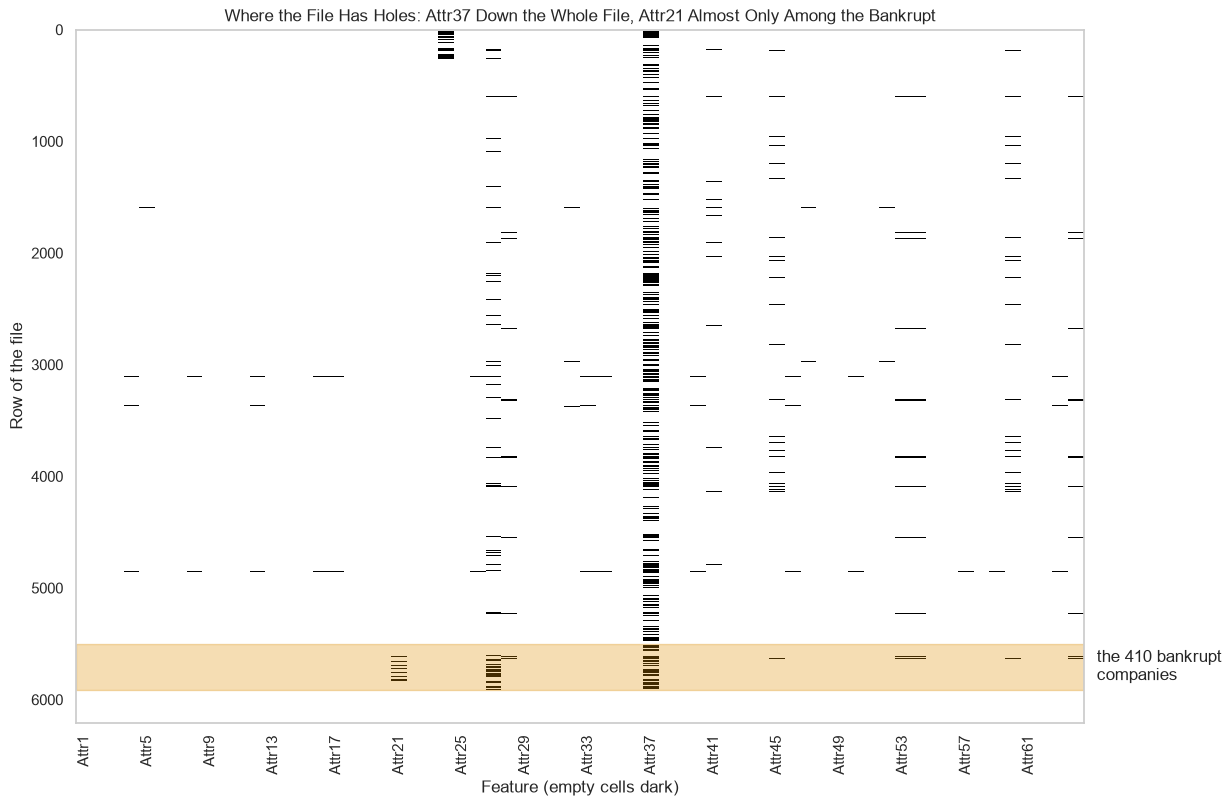

In [11]:
# every empty cell as a dark mark: the 5,910 statements down, the 64 features across
plt.figure(figsize=(13, 9))
plt.imshow(bankrupt[FEATURES].isnull(), aspect="auto", cmap="Greys", interpolation="nearest")
plt.grid(False)

# the bankrupt companies shaded, and every fourth feature named
plt.axhspan(first_bankrupt, len(bankrupt), color="C1", alpha=0.3)
plt.text(64, (first_bankrupt + len(bankrupt)) / 2, " the 410 bankrupt\n companies", va="center", fontsize=12)
plt.xticks(range(0, 64, 4), FEATURES[::4], rotation=90)
plt.xlabel("Feature (empty cells dark)")
plt.ylabel("Row of the file")
plt.title("Where the File Has Holes: Attr37 Down the Whole File, Attr21 Almost Only Among the Bankrupt")
plt.show()

The 410 bankrupt companies are the file's last rows, so a split that kept the file's order would put them all on one side.

`Attr21` (X21, this year's sales over last year's) is empty for 99 bankrupt companies and only 4 others.

**Predict 1**

Q. Among the companies where `Attr37` is empty, what share went bankrupt, in percent? And among those where it is present? Write down two numbers.

## Does a Gap Say Something?

Q. Compute both shares in percent, each with Course 1's rough margin, 1.96 x sqrt(p x (1 - p) / n), and keep them in a table `by_gap`. Store the two shares in `q3_empty` and `q3_present` (2 decimals).

Q. Draw the two shares as dots, each with its margin as a whisker, and the whole file's share as a dashed line.

In [12]:
# your code here
q3_empty = ...
q3_present = ...

# then your chart

In [13]:
check("Q3 share where empty", q3_empty, "acd4a4732702", places=2)
check("Q3 share where present", q3_present, "4268f770652c", places=2)

Q3 share where empty: not attempted yet
Q3 share where present: not attempted yet


## Copies

Q. How many rows repeat an earlier row exactly, how many of the rows with a twin are bankrupt, and how many rows repeat the 64 features but not the outcome? Store them in `q4_copies`, `q4_bankrupt` and `q4_conflicts`.

In [14]:
# your code here
q4_copies = ...
q4_bankrupt = ...
q4_conflicts = ...

In [15]:
check("Q4 copies", q4_copies, "9be8b4e0c00a", places=0)
check("Q4 bankrupt rows with a twin", q4_bankrupt, "31b5c3a27d3c", places=0)
check("Q4 conflicts", q4_conflicts, "f339131491ad", places=0)

Q4 copies: not attempted yet
Q4 bankrupt rows with a twin: not attempted yet
Q4 conflicts: not attempted yet


## Extremes

Q. Which feature holds the largest value in the file, and what is it? How many features reach above a million? Store them in `q5_column`, `q5_max` (0 decimals) and `q5_over_million`.

In [16]:
# your code here
q5_column = ...
q5_max = ...
q5_over_million = ...

In [17]:
check("Q5 column", q5_column, "b0e16315352e")
check("Q5 largest value", q5_max, "826d592ded6e", places=0)
check("Q5 features above a million", q5_over_million, "bab51638fe9e", places=0)

Q5 column: not attempted yet
Q5 largest value: not attempted yet
Q5 features above a million: not attempted yet


## How Far Every Feature Reaches

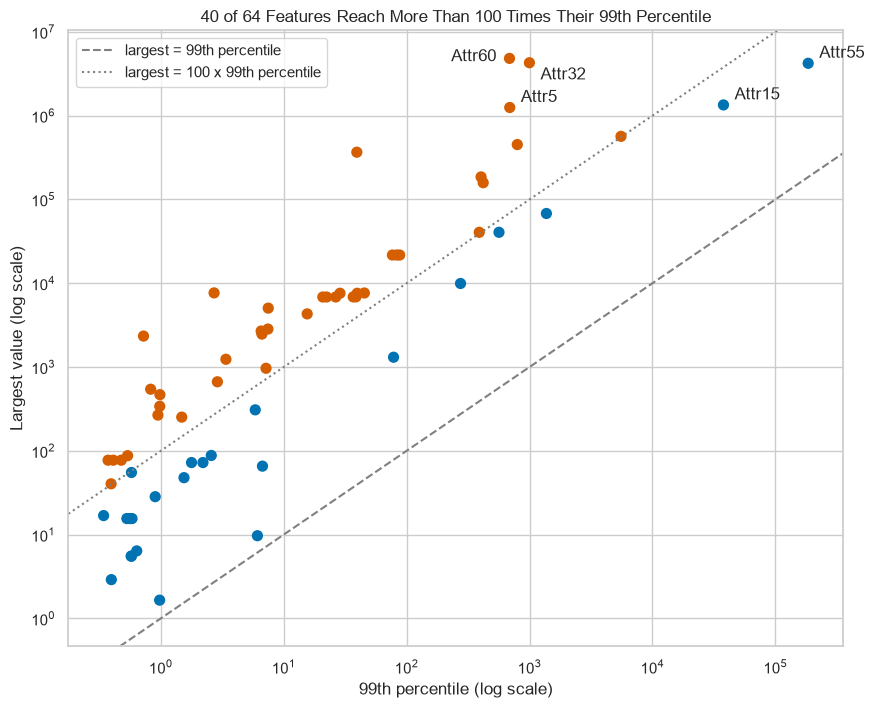

In [18]:
# each feature's largest value against its 99th percentile, log axes; red if the largest is more than 100 times it
reach = pd.DataFrame({"p99": bankrupt[FEATURES].quantile(0.99), "largest": bankrupt[FEATURES].max()})
far = reach["largest"] > 100 * reach["p99"]
plt.figure(figsize=(10, 8))
plt.scatter(reach["p99"], reach["largest"], c=far.map({True: "C3", False: "C0"}), s=50)
for name, shift in zip(reach["largest"].nlargest(5).index, [(-42, -2), (8, -12), (8, 4), (8, 4), (8, 4)]):
    plt.annotate(name, (reach.loc[name, "p99"], reach.loc[name, "largest"]), xytext=shift, textcoords="offset points")
plt.axline((1, 1), (10, 10), color="gray", linestyle="--", label="largest = 99th percentile")
plt.axline((1, 100), (10, 1000), color="gray", linestyle=":", label="largest = 100 x 99th percentile")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("99th percentile (log scale)")
plt.ylabel("Largest value (log scale)")
plt.title(f"{far.sum()} of 64 Features Reach More Than 100 Times Their 99th Percentile")
plt.legend(loc="upper left")
plt.show()

40 of the 64 features reach more than 100 times their 99th percentile.

A ratio with a denominator near zero can be enormous with nothing wrong in its arithmetic.

**The preparation needs three things: the gaps kept as columns, the copies dropped, and Day 10's quantile transform for the extremes.**

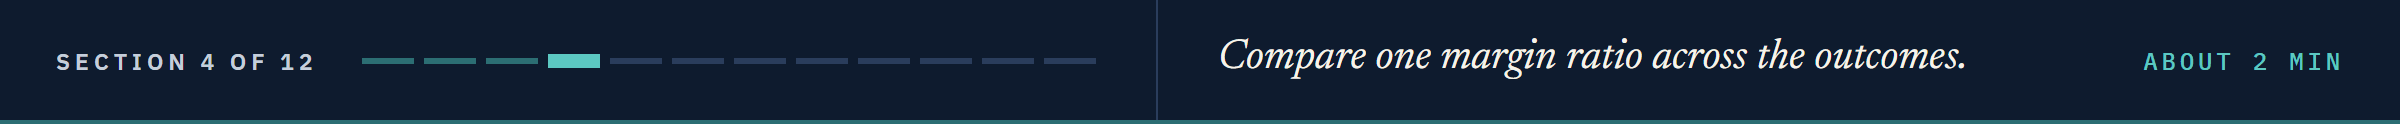

# Exploratory Data Analysis

## Profit on Sales by Outcome

Q. What is the median `Attr39` (X39, profit on sales / sales) of the companies that went bankrupt, and of those that did not? Store them in `q6_bankrupt` and `q6_survived` (4 decimals).

A **raincloud plot** stacks three views of one distribution: a half violin (the cloud), a narrow box under it, and every row as a dot (the rain).

Q. Draw a raincloud of `Attr39` for each outcome, for the companies between its 1st and 99th percentiles, the dots shifted a little with `np.random.default_rng(SEED)`.
`sns.violinplot(split=True)` with no `hue` draws half a violin, and `native_scale=True` places it at the outcome's own number, 0 or 1.

In [19]:
# your code here
q6_bankrupt = ...
q6_survived = ...

# then your chart

In [20]:
check("Q6 median, bankrupt", q6_bankrupt, "e50f63823885", places=4)
check("Q6 median, did not go bankrupt", q6_survived, "ab55130ee23c", places=4)

Q6 median, bankrupt: not attempted yet
Q6 median, did not go bankrupt: not attempted yet


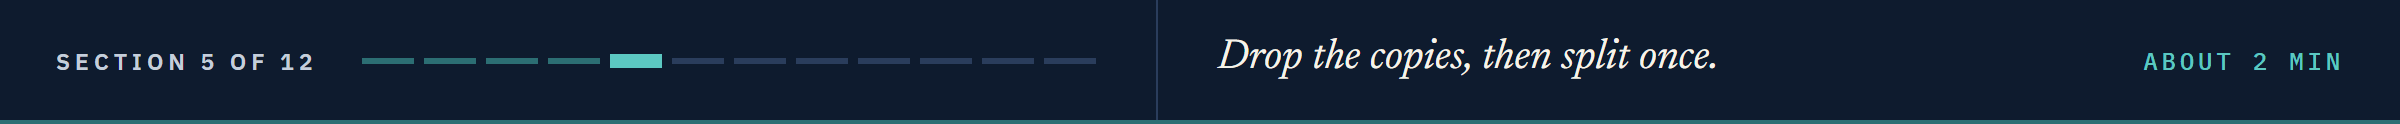

# Data Preparation for Modeling

## Copies Out, Then One Split

Q. Drop the exact copies, then split the rest 80/20 into `X_train, X_test, y_train, y_test` with `stratify=y` and the course seed. Store the number of training rows in `q7_train_rows` and of test bankruptcies in `q7_test_bankrupt`.

In [21]:
# your code here
q7_train_rows = ...
q7_test_bankrupt = ...

In [22]:
check("Q7 training rows", q7_train_rows, "e406c5a57ef9", places=0)
check("Q7 test bankruptcies", q7_test_bankrupt, "b809cf3f69ed", places=0)

Q7 training rows: not attempted yet
Q7 test bankruptcies: not attempted yet


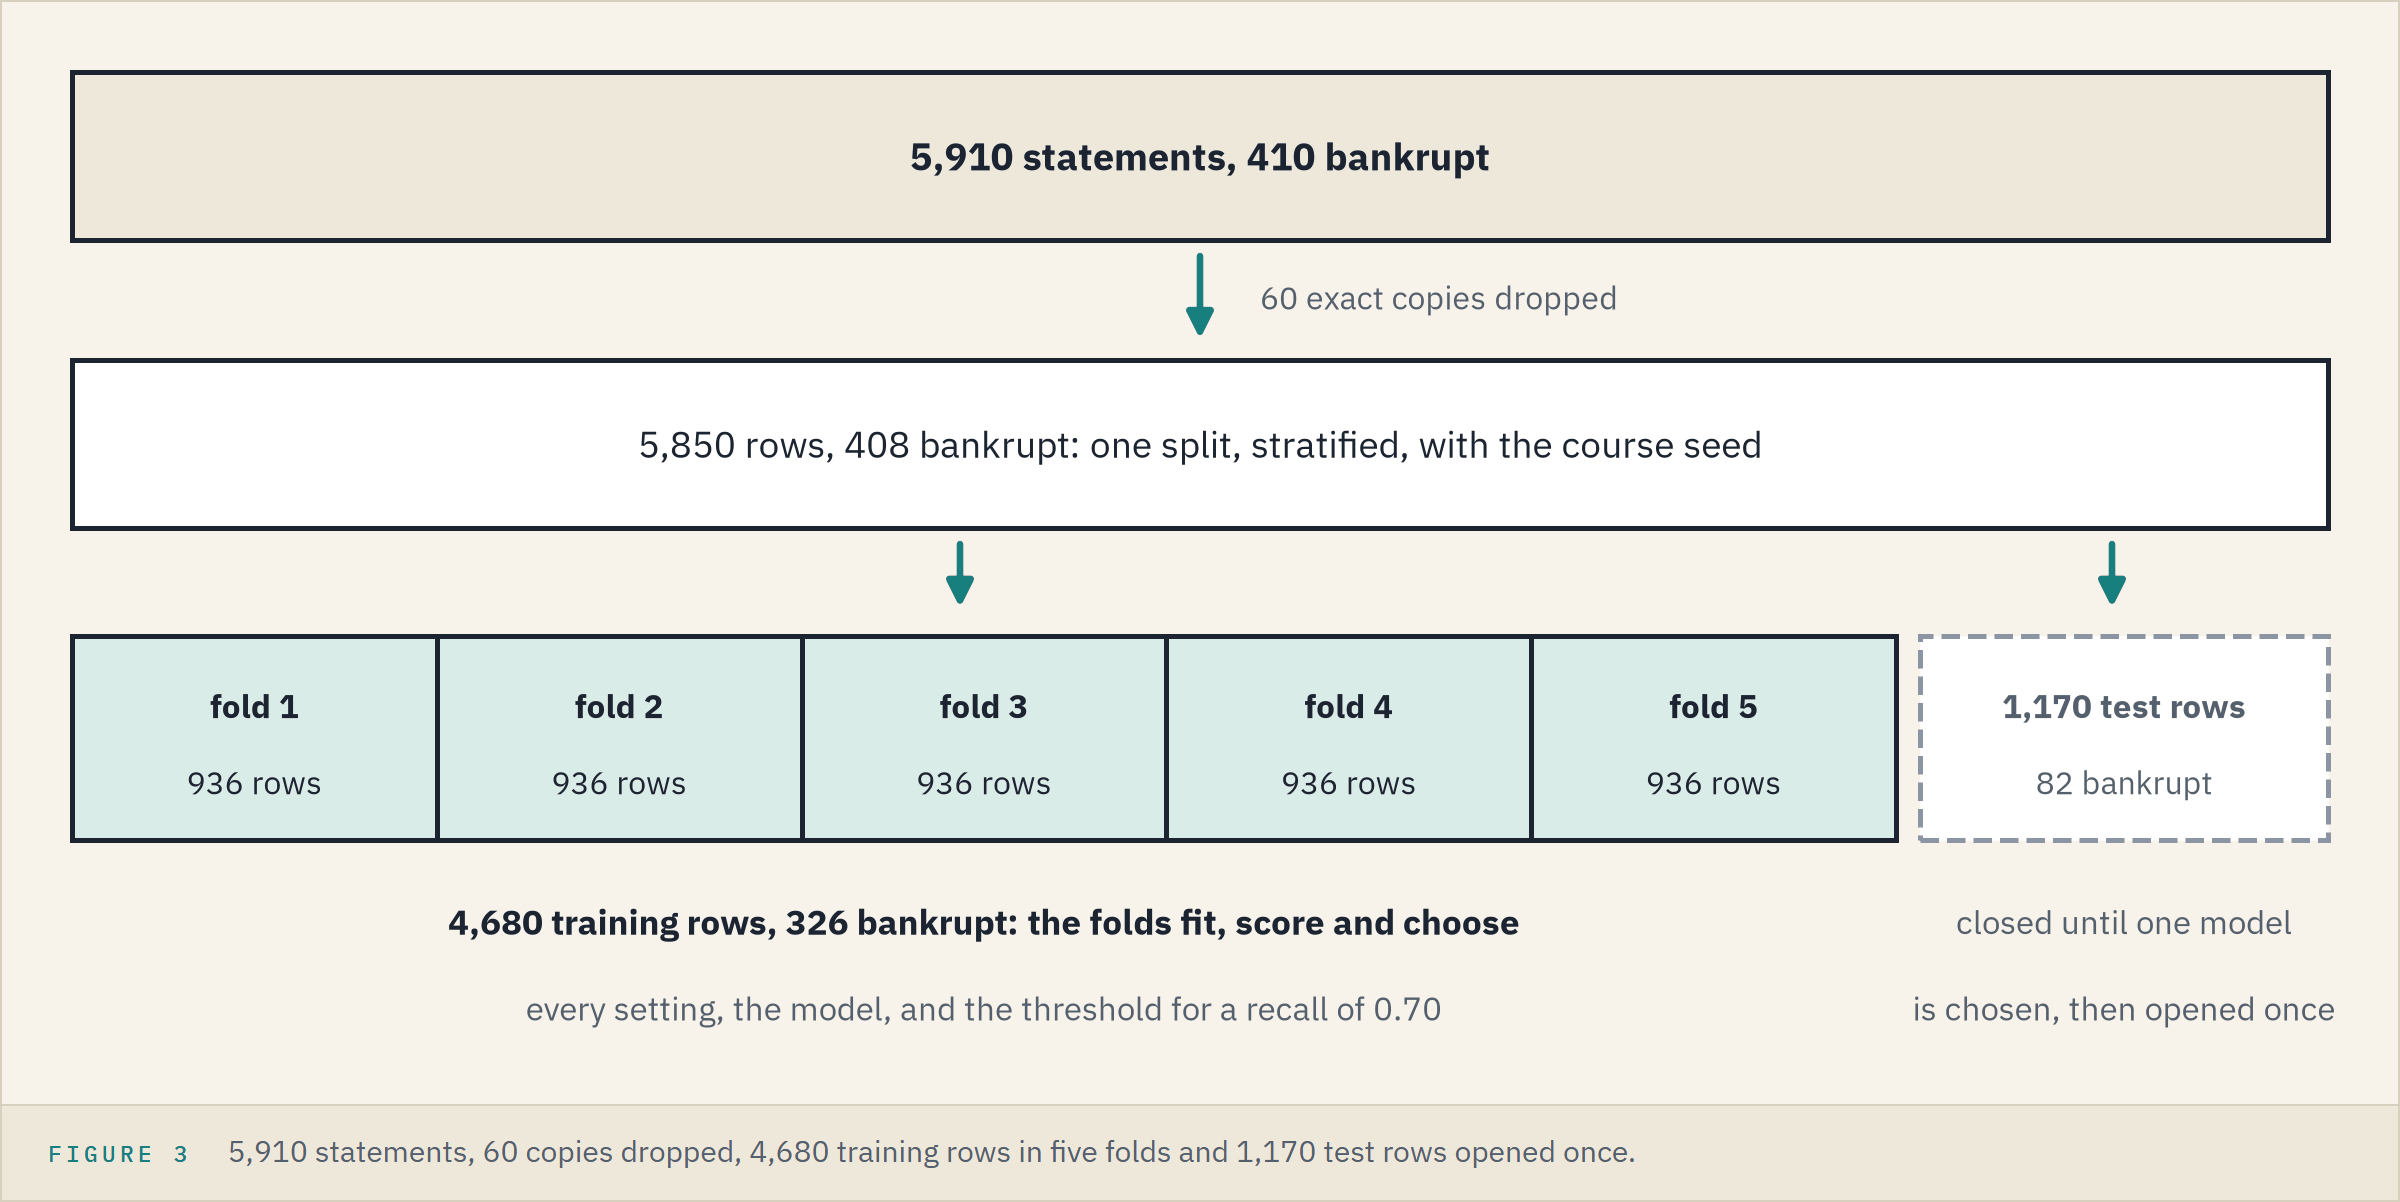

**Every choice from here is made on the 4,680 training rows; the 1,170 test rows stay closed until one model is chosen.**

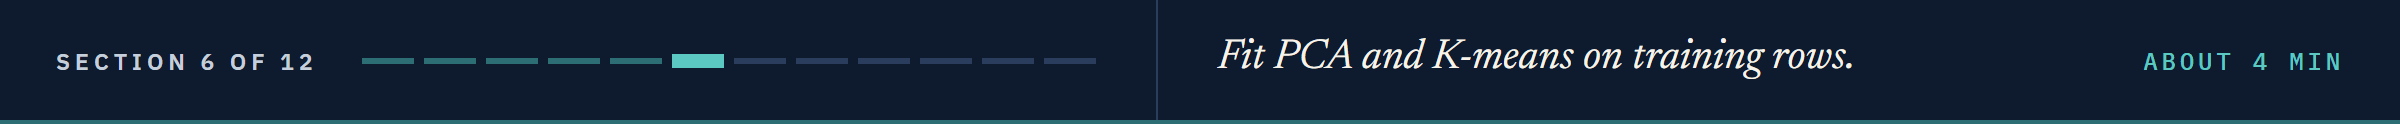

# A Look Without the Label

PCA and K-means never see the outcome.
Fitted on the training rows only, they show whether the features alone sort the companies.

**Predict 2**

Q. PCA turns the 64 features into 64 directions, largest first. How many directions does it take to reach 80 percent of the variance? Write down a number.

## Many Features, Few Directions

The quantile transform puts every feature on one scale, normal scores, so no feature's extremes take over a direction.

`SimpleImputer(strategy="median")` fills each gap with its column's median, learned at `fit` from the rows it is given.

Q. Fit a pipeline of that imputer, Day 10's quantile transform and Day 14's `PCA(random_state=SEED)` on `X_train` (steps `"impute"`, `"quantile"`, `"pca"`), keeping its output as `train_scores`. Store the first component's share of the variance in percent in `q8_first` (2 decimals) and the components that reach 80 percent in `q8_components`.

Q. Draw Day 14's scree plot of the first 20 components: each one's share as a bar, the running total as a line, and 80 percent dashed.

In [23]:
# your code here
q8_first = ...
q8_components = ...

# then your chart

In [24]:
check("Q8 first component", q8_first, "e9dd83ed54ab", places=2)
check("Q8 components for 80 percent", q8_components, "bcc20ea213a8", places=0)

Q8 first component: not attempted yet
Q8 components for 80 percent: not attempted yet


## Four Clusters on Two Components

Q. Run Day 12's `KMeans(n_clusters=4, n_init=10, random_state=SEED)` on the first two columns of `train_scores`, numbering the clusters by size, largest 0, as Day 12 does. Give each cluster's size, bankruptcies and bankrupt share in percent in a table `profile`. Store the highest share in `q9_top_share` (2 decimals) and that cluster's bankruptcies in `q9_top_count`.

Q. Draw the training companies on the two components with each cluster's area shaded (Day 12's nearest-centre tiles: `contourf` over a grid, each point given its cluster by `kmeans.predict`), the bankrupt companies dark, and each area's size and bankrupt share in the key.

In [25]:
# your code here
q9_top_share = ...
q9_top_count = ...

# then your chart

In [26]:
check("Q9 highest bankrupt share", q9_top_share, "302e9cfc9b18", places=2)
check("Q9 bankruptcies in that cluster", q9_top_count, "4e9a90a6fddd", places=0)

Q9 highest bankrupt share: not attempted yet
Q9 bankruptcies in that cluster: not attempted yet


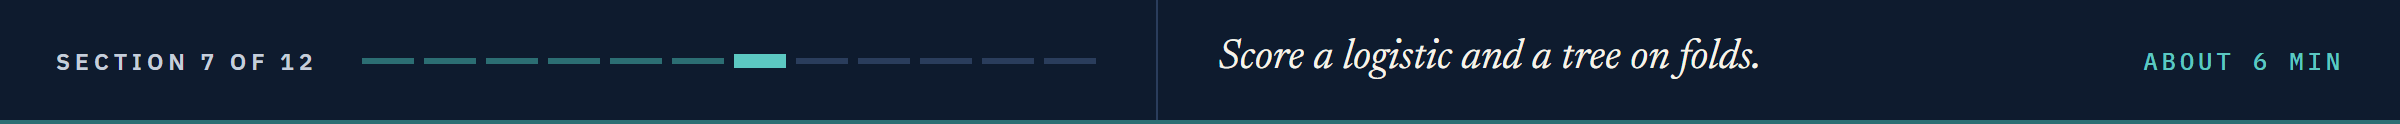

# Model Building

## Model Evaluation Criterion

A missed bankruptcy and a flagged survivor are both errors (Day 7), with no money attached here.

About 7 percent went bankrupt, so a model that flags nobody is right 93 percent of the time.

With so rare a label ROC AUC can stay high while the top of the ranking is crowded with survivors, so models are ranked by **average precision** (Day 8) on five folds of the training rows.

Each model then gets a threshold for a recall of 0.70, the desk's illustration.

## The Scoring Function

Day 8's scoring function with average precision added first: the label is rare, so the score that reads the top of the ranking leads.

In [27]:
# flag at or above the threshold, then average precision, ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "Average precision": [average_precision_score(target, model.predict_proba(predictors)[:, 1])],
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

## Two Pipelines, One Imputer

With `add_indicator=True` the median imputer also adds a 0/1 **missing indicator** column for each feature with a gap in the rows it was fitted on.
All three models start with it.

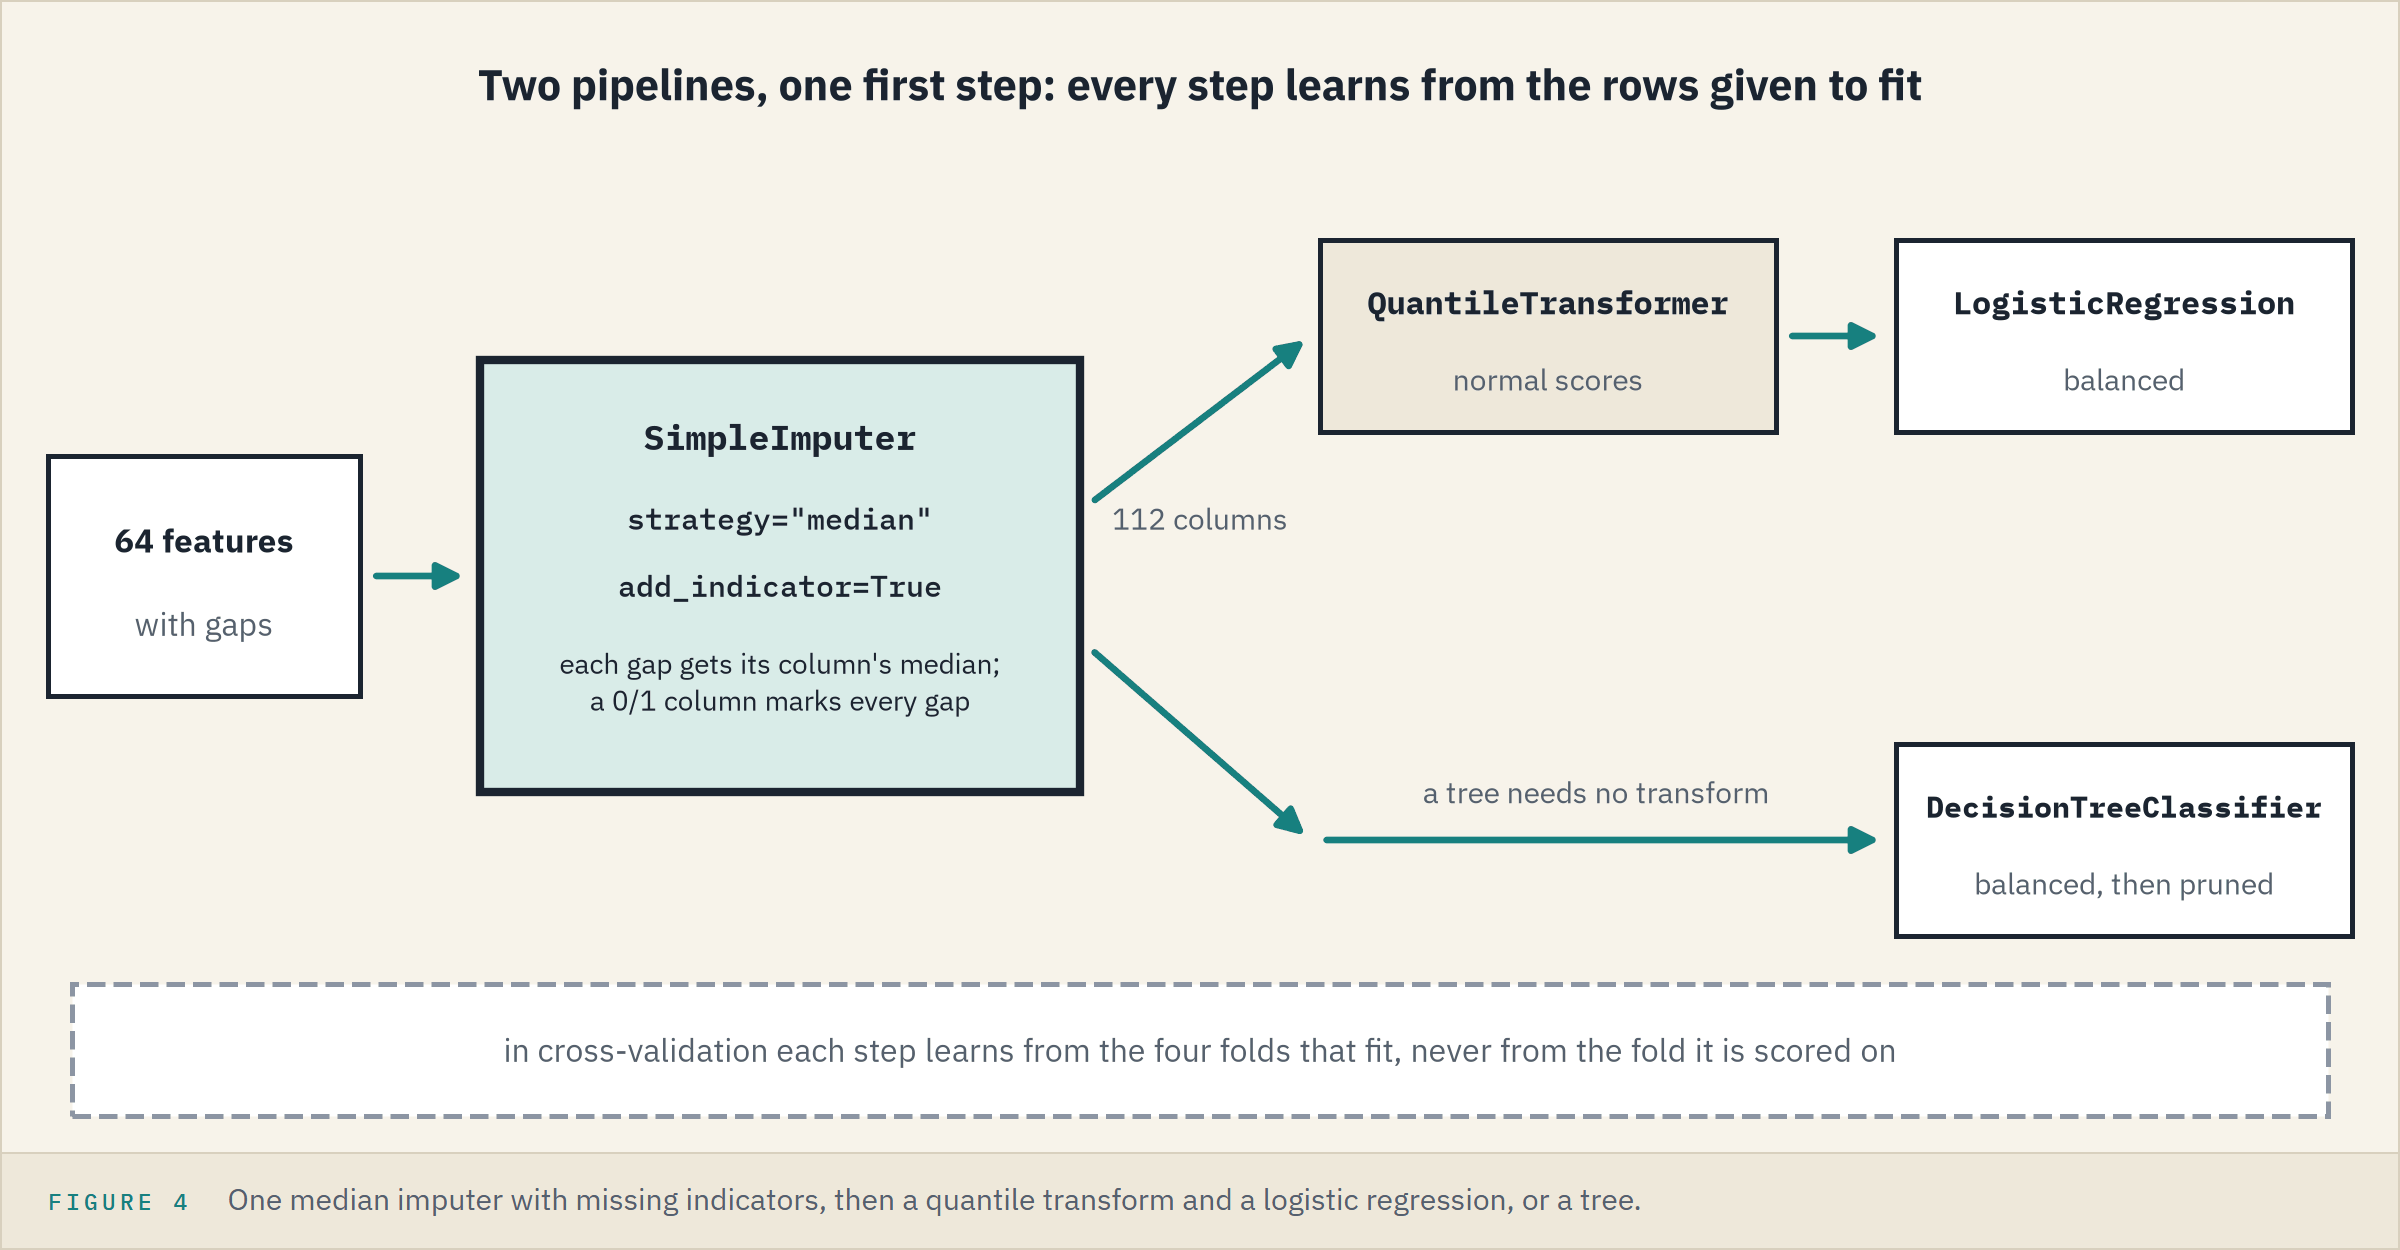

## Logistic Regression

`solver="newton-cholesky"` with `tol=1e-8` fits the logistic regression to the same coefficients on every machine; the default solver stops short on 112 related columns.

Q. Build `logistic`, a pipeline of that imputer, Day 10's quantile transform and `LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced")` (steps `"impute"`, `"quantile"`, `"logit"`). Score it with Day 5's `cross_validate` on Day 9's stratified folds, `folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`, scoring `["average_precision", "roc_auc"]`: the fold scores come back under `"test_average_precision"` and `"test_roc_auc"`. Store the mean scores in `q10_ap` and `q10_auc` (4 decimals).

In [28]:
# your code here
q10_ap = ...
q10_auc = ...

In [29]:
check("Q10 fold average precision", q10_ap, "225adef27f00", places=4)
check("Q10 fold ROC AUC", q10_auc, "c47217f103c7", places=4)

Q10 fold average precision: not attempted yet
Q10 fold ROC AUC: not attempted yet


**Predict 3**

Q. Drop the missing indicators and keep everything else. Write down the fold average precision, against 0.6624 with them.

## What the Indicators Are Worth

Q. Score the same pipeline with `add_indicator=False` on the same folds. Store its mean average precision in `q11_ap` (4 decimals).

In [30]:
# your code here
q11_ap = ...

In [31]:
check("Q11 fold average precision without indicators", q11_ap, "3b344da74d95", places=4)

Q11 fold average precision without indicators: not attempted yet


## A Default Tree

Q. Build `tree`, a pipeline of the same imputer and `DecisionTreeClassifier(class_weight="balanced", random_state=SEED)` (steps `"impute"`, `"tree"`). Fit it on the training rows and cross-validate it. Store its leaves in `q12_leaves` and its fold average precision in `q12_ap` (4 decimals).

In [32]:
# your code here
q12_leaves = ...
q12_ap = ...

In [33]:
check("Q12 leaves", q12_leaves, "820f96e15ea0", places=0)
check("Q12 fold average precision", q12_ap, "b77f18744ae6", places=4)

Q12 leaves: not attempted yet
Q12 fold average precision: not attempted yet


**The tree is pruned next, two ways, each chosen on the folds.**

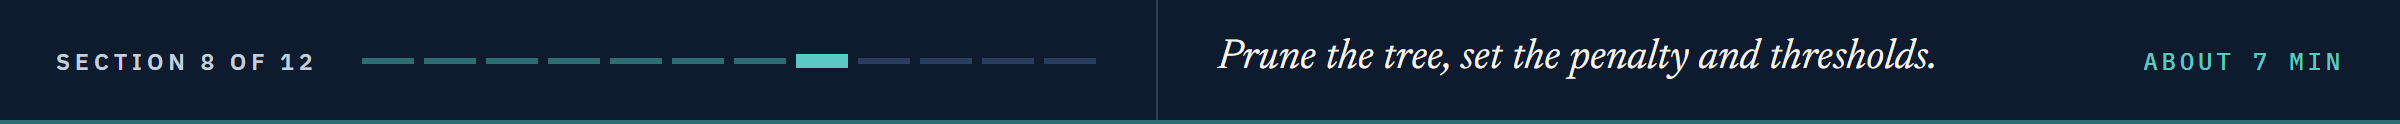

# Model Performance Improvement

## Pre-Pruning

In a grid for a pipeline, a step's setting is named with the step, two underscores and the setting: `tree__max_depth`.

Q. Search `max_depth` 4, 6, 8, 10 and `min_samples_leaf` 10, 20, 40 for `tree` with Day 9's `GridSearchCV` on `folds`, scoring `"average_precision"`, as `pre_search`. Keep the best pipeline as `pre_pruned`. Store its depth, its smallest leaf and its fold score in `q13_depth`, `q13_leaf` and `q13_ap` (4 decimals).

Q. Draw the twelve fold scores as an annotated heatmap, depth down and leaf size across, with the best cell outlined.

In [34]:
# your code here
q13_depth = ...
q13_leaf = ...
q13_ap = ...

# then your chart

In [35]:
check("Q13 depth", q13_depth, "deca657f3c78", places=0)
check("Q13 smallest leaf", q13_leaf, "d9934faa9ed2", places=0)
check("Q13 fold average precision", q13_ap, "1d794fdc4eb5", places=4)

Q13 depth: not attempted yet
Q13 smallest leaf: not attempted yet
Q13 fold average precision: not attempted yet


## Post-Pruning

Q. Search `ccp_alpha` 0.0005, 0.001, 0.002, 0.003, 0.005, 0.01 for `tree` the same way, as `post_search`, and keep the best pipeline as `post_pruned`. Store the best `ccp_alpha` in `q14_alpha` (4 decimals), its fold score in `q14_ap` (4 decimals) and its leaves in `q14_leaves`.

In [36]:
# your code here
q14_alpha = ...
q14_ap = ...
q14_leaves = ...

In [37]:
check("Q14 ccp_alpha", q14_alpha, "77b8b3f1f2b7", places=4)
check("Q14 fold average precision", q14_ap, "ad320764e6c6", places=4)
check("Q14 leaves", q14_leaves, "90cf66d1240b", places=0)

Q14 ccp_alpha: not attempted yet
Q14 fold average precision: not attempted yet
Q14 leaves: not attempted yet


## The Penalty

Days 5 and 6 had one more dial: the penalty.

In `LogisticRegression` a smaller `C` shrinks the coefficients harder.

Q. Search `logit__C` 0.01, 0.1, 1.0, 10.0 for `logistic` the same way, as `c_search`. Store the best `C` in `q15_c` (2 decimals).

Q. Draw the fold score against `C` and against `ccp_alpha`, as two panels with log axes across, each chosen value ringed.

In [38]:
# your code here
q15_c = ...

# then your chart

In [39]:
check("Q15 best C", q15_c, "c4cac4d1653a", places=2)

Q15 best C: not attempted yet


## Thresholds for a Recall of 0.70

Day 8 set its threshold on validation rows.
Here the folds do that job: `cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")` fits the model five times and gives each training company the probability from the fit that did not see it, an **out-of-fold** probability.

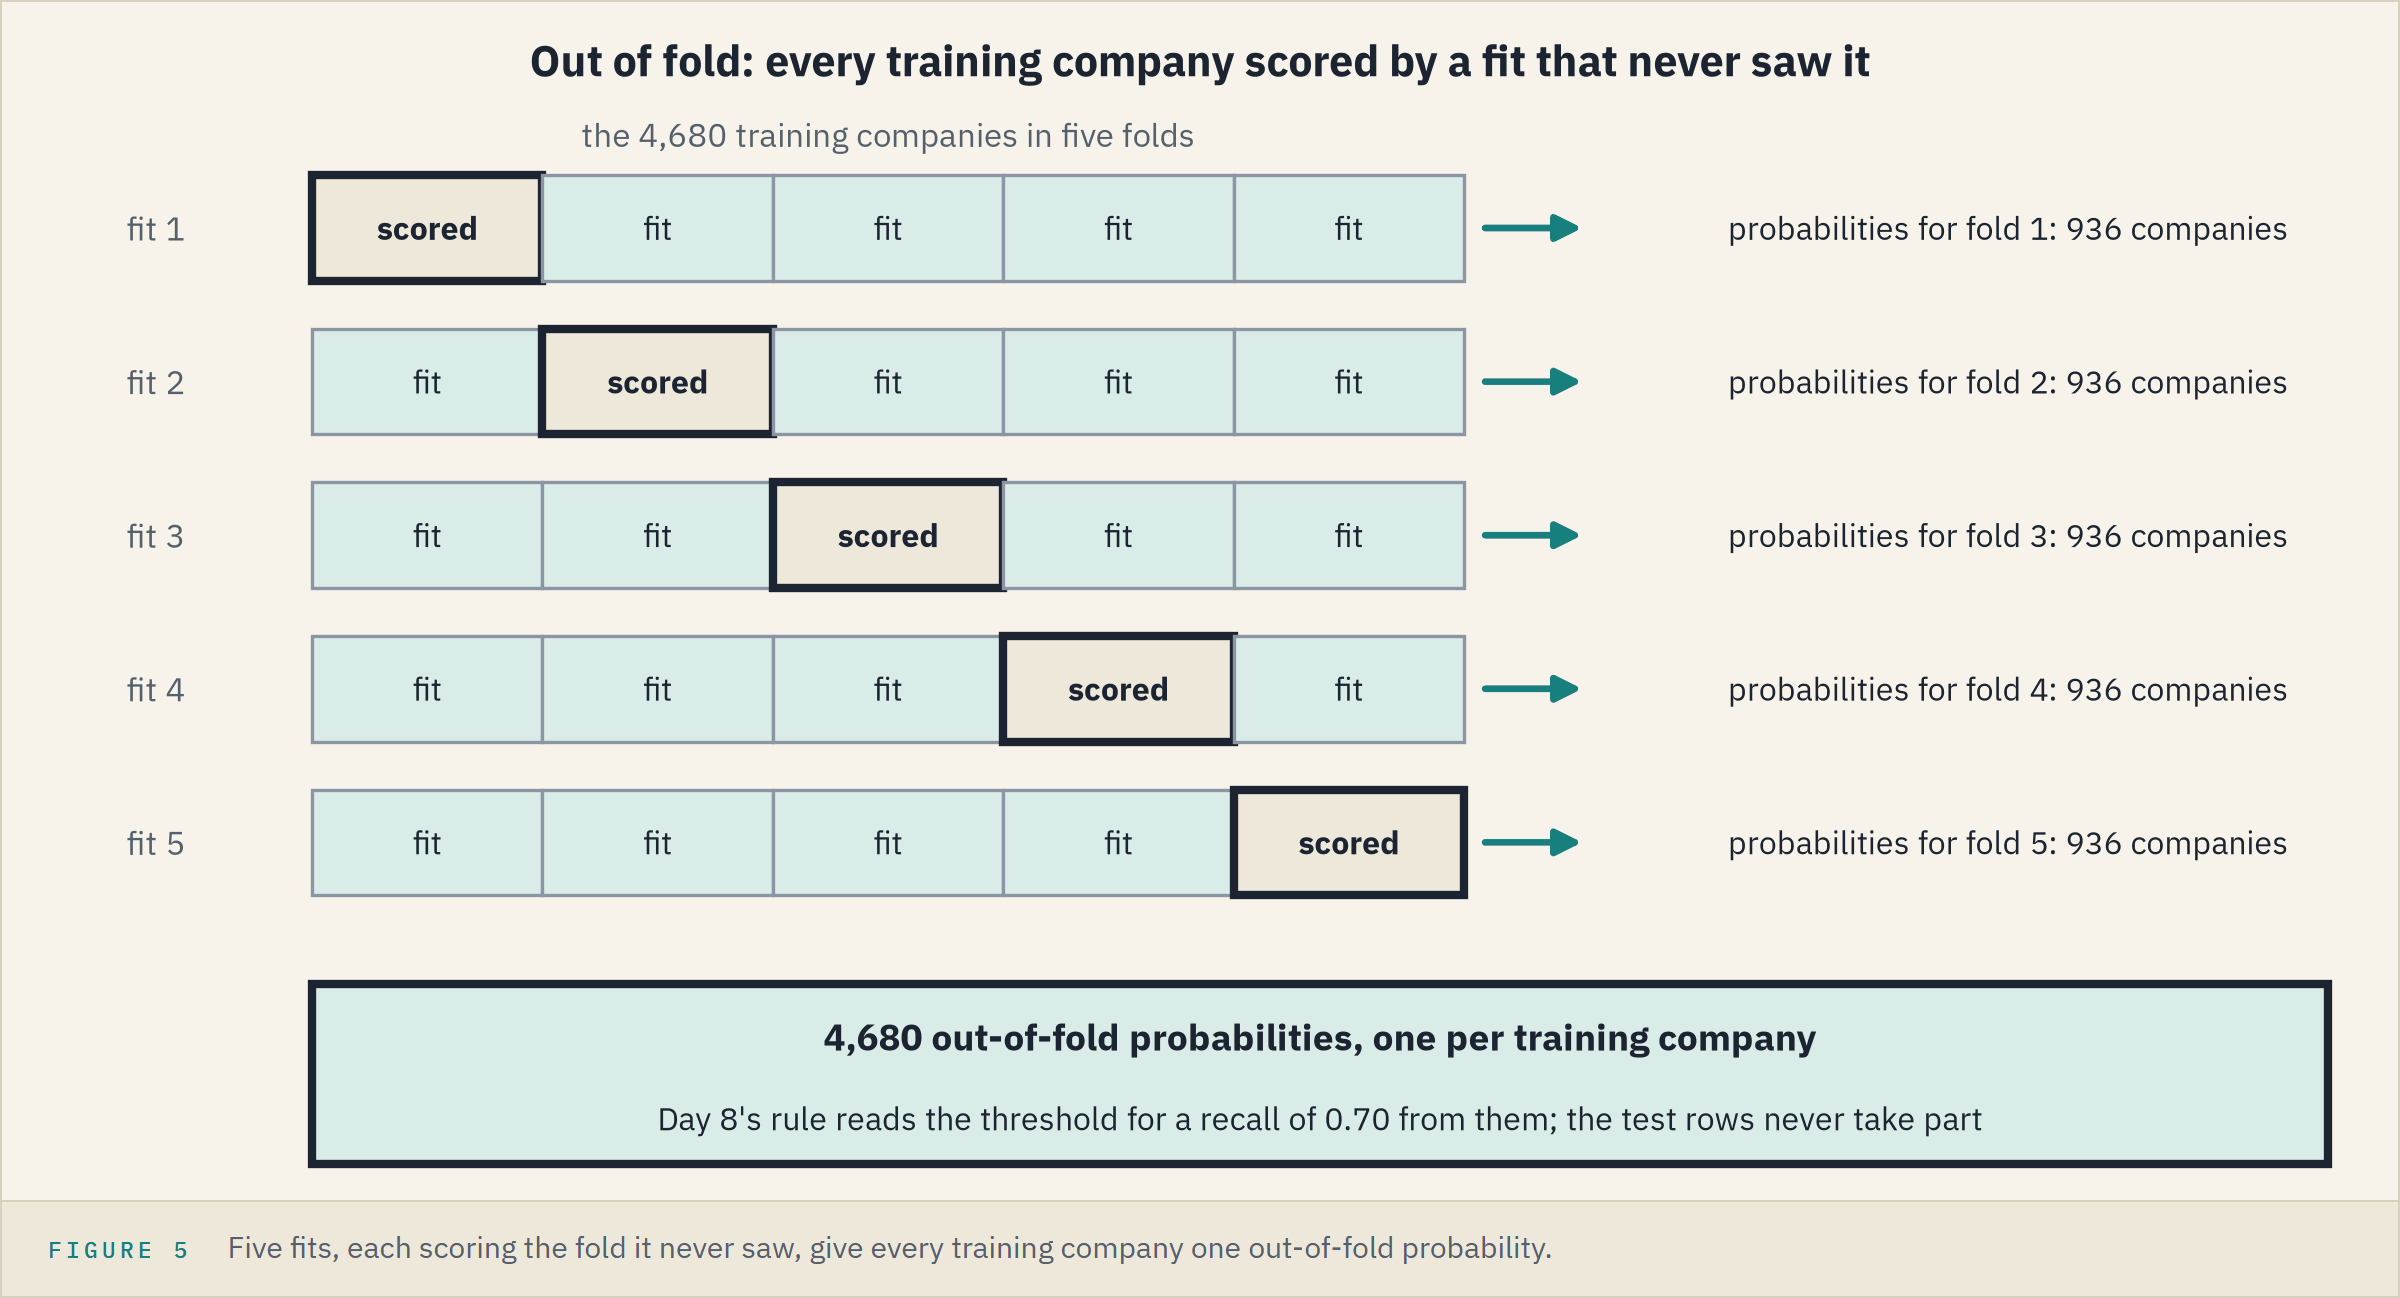

Q. Put the three models in a dictionary `models` under the keys `"logistic"`, `"pre-pruned tree"` and `"post-pruned tree"`. Keep each one's out-of-fold probabilities in a dictionary `out_of_fold` and its threshold for a recall of 0.70 by Day 8's rule in `thresholds_70`. Store the thresholds in `q16_logistic`, `q16_pre` and `q16_post` (4 decimals).

Q. Draw the three out-of-fold precision-recall curves on one chart, recall 0.70 dashed and each model's threshold as a dot.

In [40]:
# your code here
q16_logistic = ...
q16_pre = ...
q16_post = ...

# then your chart

In [41]:
check("Q16 logistic threshold", q16_logistic, "e2e6e9d8ca50", places=4)
check("Q16 pre-pruned threshold", q16_pre, "8765d4564dbe", places=4)
check("Q16 post-pruned threshold", q16_post, "66bfa7576242", places=4)

Q16 logistic threshold: not attempted yet
Q16 pre-pruned threshold: not attempted yet
Q16 post-pruned threshold: not attempted yet


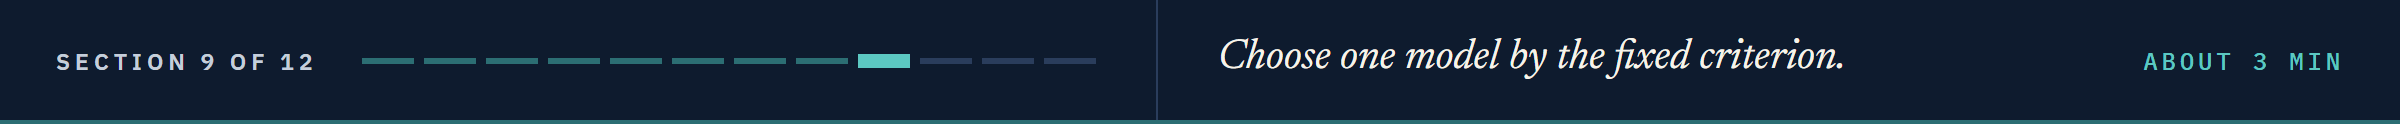

# Final Model Selection

The criterion was set before any model was fitted: fold average precision first.

**Predict 4**

Q. Score each model on the training rows it was fitted on. Which one has the highest average precision there, and what is it? Write down a name and a number.

## Judged on Their Own Rows

Q. Fit `logistic` on the training rows (the searches already refitted the trees), and score all three there with the scoring function, each at its threshold. Set each training-row average precision beside its fold score in a table `gap_table`. Store the key of the model highest on the training rows in `q17_model` and its score in `q17_ap` (4 decimals).

In [42]:
# your code here
q17_model = ...
q17_ap = ...

In [43]:
check("Q17 model with the highest training-row score", q17_model, "fa9e2d519e4c")
check("Q17 its training-row average precision", q17_ap, "70959b8c257a", places=4)

Q17 model with the highest training-row score: not attempted yet
Q17 its training-row average precision: not attempted yet


## The Choice

Q. Which model goes forward, by the criterion set before any model was fitted? Store its key in `models` in `q18_choice`, and write one reason a line.

In [44]:
# your code here
q18_choice = ...

In [45]:
check("Q18 the choice", q18_choice, "ad44a3ef2bb1")

Q18 the choice: not attempted yet


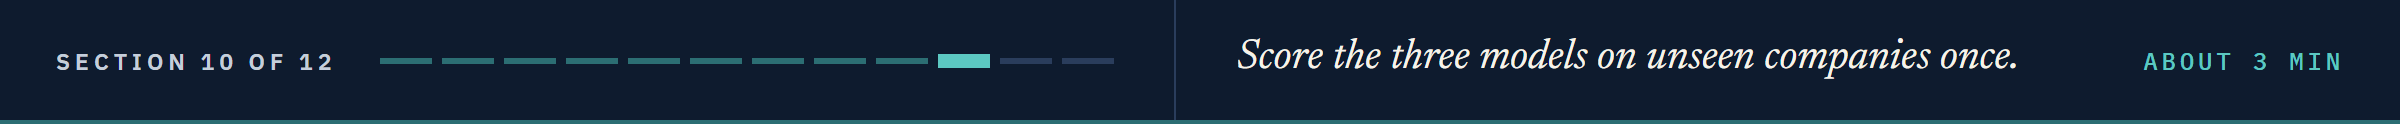

# The Test Rows, Opened Once

**Predict 5**

Out of fold, the logistic's threshold of 0.7134 catches 70.25 percent of the 326 training bankruptcies.

Q. How many of the 82 test bankruptcies does it flag?

## The Test Table

Q. Score the three models on the test rows in one table, `test_comp`, each at its threshold, and keep each model's test flags in a dictionary `test_flags`. Store the number of test bankruptcies the logistic flags in `q19_caught` and its test average precision in `q19_ap` (4 decimals).

Q. Draw the three test confusion matrices side by side in Day 7's four colours.

A **bump chart** ranks the models on each measure, first at the top, and joins each model's ranks with a line.

Q. Draw a bump chart of the models' ranks on training-row and fold average precision and on the test table's average precision, ROC AUC, recall and precision.

In [46]:
# your code here
q19_caught = ...
q19_ap = ...

# then your two charts

In [47]:
check("Q19 test bankruptcies flagged", q19_caught, "0ed5a337397e", places=0)
check("Q19 test average precision", q19_ap, "018f83cc6d60", places=4)

Q19 test bankruptcies flagged: not attempted yet
Q19 test average precision: not attempted yet


## Which Bankruptcies Each Model Catches

Q. For each of the 82 test bankruptcies, note which models flag it, in a table `caught` with one column per model. Store how many all three flag in `q20_all` and how many none flags in `q20_none`.

An **UpSet chart** counts overlapping groups: one bar per pattern, and under each bar a dot for every model in the pattern.

Q. Draw an UpSet chart of the patterns in `caught`.

In [48]:
# your code here
q20_all = ...
q20_none = ...

# then your chart

In [49]:
check("Q20 caught by all three", q20_all, "e2ffe8520eb9", places=0)
check("Q20 caught by none", q20_none, "edd66b199bc3", places=0)

Q20 caught by all three: not attempted yet
Q20 caught by none: not attempted yet


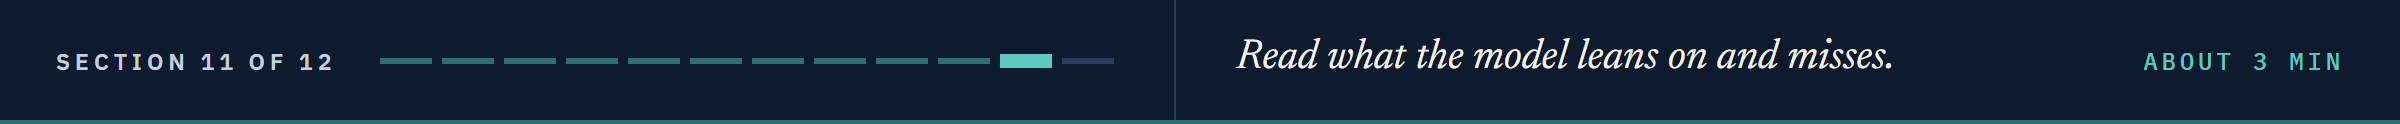

# Where the Model Fails

## What It Leans On

Q. Name the 112 columns with `logistic["impute"].get_feature_names_out()`. Take the fitted logistic's ten largest coefficients by size and the pre-pruned tree's ten largest importances, as Series `top_coefficients` and `top_importances`. How many columns are in both? Store it in `q21_common`.

Q. Draw the two top tens as lollipops side by side, the coefficients coloured by sign.

In [50]:
# your code here
q21_common = ...

# then your chart

In [51]:
check("Q21 columns in both top tens", q21_common, "405250f71bc2", places=0)

Q21 columns in both top tens: not attempted yet


## The Misses

Q. Which test bankruptcies does the logistic miss at its threshold? Store how many in `q22_missed`, and how many of them still show a positive `Attr39` in `q22_positive`.

In [52]:
# your code here
q22_missed = ...
q22_positive = ...

In [53]:
check("Q22 missed", q22_missed, "8cd4bde8507f", places=0)
check("Q22 missed with a positive Attr39", q22_positive, "96d187df201b", places=0)

Q22 missed: not attempted yet
Q22 missed with a positive Attr39: not attempted yet


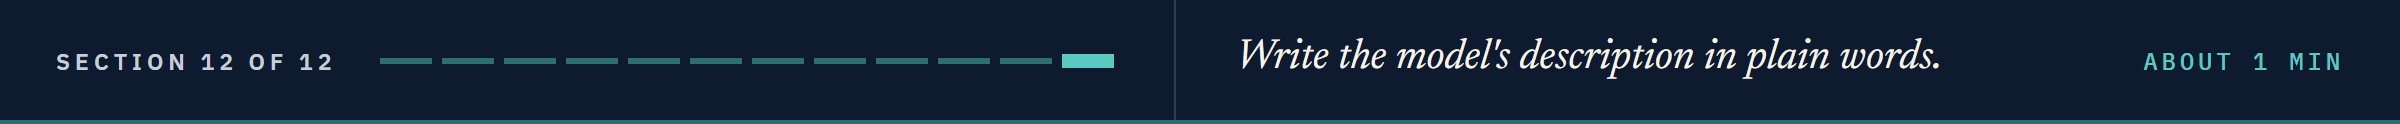

# Insights and Conclusion

## The Description

Q. Write `description`, one string of a few sentences: what the chosen model separates and how well on the test rows, where it is wrong, what the data cannot support, and what was not tested. Then run the cell under it.

In [54]:
# your description here
description = ...

In [55]:
# a reminder, not a proof: words that would turn a description into a view on a company
WATCH = ["forecast", "will go bankrupt", "will default", "cheap", "rich", "signal", "recommend", "should"]  # words this description never uses
found = [word for word in WATCH if word in str(description).lower()]
print("Words from the list in the description:", found)

Words from the list in the description: []


**A model describes the file it was fitted on.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Run a whole classification job on a real file, every choice made on training rows.
* Fill gaps inside a pipeline with `SimpleImputer` and its missing indicators.
* Read a file without its label with PCA and K-means.
* Choose settings with `GridSearchCV` on a pipeline, and a threshold from out-of-fold probabilities.
* Say what a model leans on and where it fails.

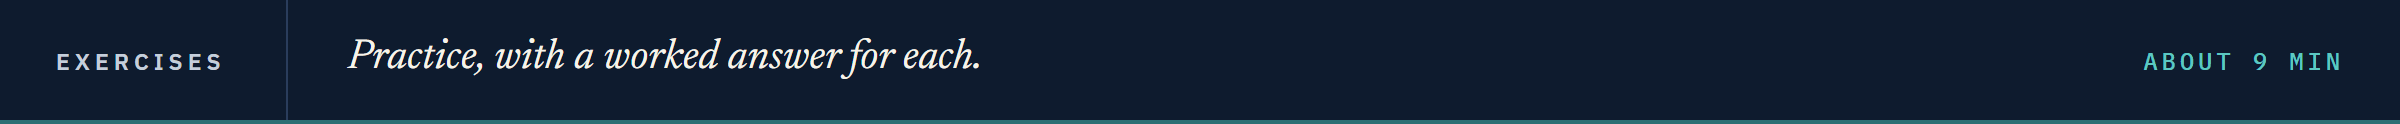

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

`check()` from Setting Up marks each answer.

### Exercise 1

**A Recall Target of 0.80**

Q. Find the logistic's out-of-fold threshold for a recall of 0.80 by Day 8's rule, and the training companies it flags. Store them in `ex1_threshold` (4 decimals) and `ex1_flagged`.

In [56]:
# your code here
ex1_threshold = ...
ex1_flagged = ...

In [57]:
check("Exercise 1 threshold", ex1_threshold, "32ffc66163a4", places=4)
check("Exercise 1 flagged", ex1_flagged, "48a5e6472744", places=0)

Exercise 1 threshold: not attempted yet
Exercise 1 flagged: not attempted yet


### Exercise 2

**PCA Inside the Pipeline**

Q. Put `PCA(n_components=20, random_state=SEED)` between the quantile transform and the logistic regression, and score the pipeline on the folds. Store its mean average precision in `ex2_ap` (4 decimals).

In [58]:
# your code here
ex2_ap = ...

In [59]:
check("Exercise 2 fold average precision", ex2_ap, "1a0651c6df50", places=4)

Exercise 2 fold average precision: not attempted yet


### Exercise 3: AI check

**Medians From Where?**

You asked an AI assistant for a function that drops the copies, fills every gap with the training rows' median, and splits 80/20.
This came back.
It runs, and its comments sound careful.
Test it, then find the one bug.
`.statistics_` holds the medians an imputer learned at `fit`.

In [60]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def prepare_with_medians(rows):
    # drop the copies, fill every gap with the training rows' median, then split 80/20 with the seed
    rows = rows.drop_duplicates()
    imputer = SimpleImputer(strategy="median").fit(rows[FEATURES])
    filled = pd.DataFrame(imputer.transform(rows[FEATURES]), columns=FEATURES, index=rows.index)
    X_tr, X_te, y_tr, y_te = train_test_split(filled, rows[TARGET], test_size=0.2, stratify=rows[TARGET], random_state=SEED)
    return X_tr, X_te, y_tr, y_te, imputer

In [61]:
# the test: the imputer's 64 medians must be the training rows' own (empty cells skipped)
ai_train, ai_test, ai_y_train, ai_y_test, ai_imputer = prepare_with_medians(bankrupt)
own = bankrupt.loc[ai_train.index, FEATURES].median()
differing = (~np.isclose(ai_imputer.statistics_, own)).sum()
assert differing == 0, f"{differing} of the 64 medians are not the training rows' own"

AssertionError: 63 of the 64 medians are not the training rows' own

Q. Fix the function: split first, then learn the medians from the training rows only. Store the number of medians that differ from the training rows' own after the fix in `ex3_differing`.

In [62]:
# your code here
ex3_differing = ...

In [63]:
check("Exercise 3 medians differing after the fix", ex3_differing, "17e99f1802e2", places=0)

Exercise 3 medians differing after the fix: not attempted yet


## Congratulations!

You ran the whole course on one real file, and the work was yours.
You found gaps that say something, copies, and values in the millions, and handled each inside a pipeline.
You chose every setting and a threshold on the folds alone, opened the test rows once, and the numbers held.
Course 5 grows forests and boosting from a single tree, and these 4,680 training rows come back.

[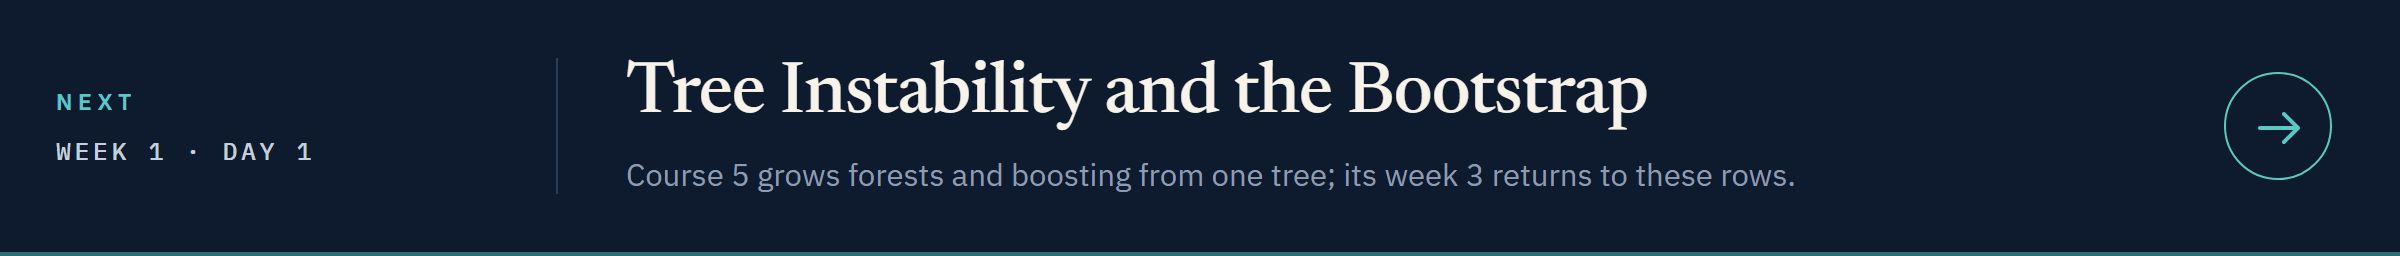](../../../course05_advanced_ml/week1/day1/01_tree_instability_and_the_bootstrap.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day1/01_tree_instability_and_the_bootstrap.ipynb)